# Overlapping Vessel Recordings and a Frozen ResNet50-Based Classifier

Ths code measures how synthetic waveform overlap changes an existing classifier's outputs. No training, fine-tuning, threshold fitting, output-layer replacement or feature-representation redesign is performed. All computations are performed with CPU only.

This project uses/adapts components of DAT255.

Original project: https://github.com/voibit/DAT255
Author: Jan-Kristian Mathisen
Copyright (c) 2022 Jan-Kristian Mathisen
License: MIT License

The original MIT License is available at:
https://github.com/voibit/DAT255/blob/main/LICENSE
</br>
</br>
The testing data used is from the Deepship dataset:

DeepShip Dataset:
    Irfan, M., Jiangbin, Z., Ali, S., Iqbal, M., Masood, Z., & Hamid, U. (2021).
    DeepShip: An underwater acoustic benchmark dataset and a separable
    convolution based autoencoder for classification.
    Expert Systems with Applications, 183, 115270.
    DOI: https://doi.org/10.1016/j.eswa.2021.115270

Dataset repository: https://github.com/irfankamboh/DeepShip


> **Training-data limitation:** The ResNet50-based was trained on DeepShip. These source
> recordings may already have appeared in its training data. This is a robustness
> experiment on the available recordings, not evidence of unseen-vessel
> generalisation. A new split cannot establish that the model has never seen them.

There are also only three tug source recordings. Scenarios reuse recordings and sometimes the same vessel. Their count is not an independent sample size. All results below are descriptive. There are no naive independent-trial significance tests or confidence intervals.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Audio

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'DeepShip').is_dir())
sys.path.insert(0, str(ROOT / 'dat255_pilot'))
import overlap_experiments as ex
import dat255_cpu as cpu
import torch, soundfile as sf
torch.set_num_threads(8)
import matplotlib.pyplot as plt
%matplotlib inline

RESULTS = ROOT / 'dat255_pilot' / 'overlap_results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'font.size': 10})
pd.set_option('display.max_columns', 16)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=170, bbox_inches='tight')
    plt.show()

print('Python:', sys.executable)
print('Torch:', torch.__version__, '| CUDA used: False | model batch size: 1')

Python: c:\Documents (Local only)\Intel NUC\Documents\USYD\ELEC5305\.venv-dat255\Scripts\python.exe
Torch: 2.6.0+cpu | CUDA used: False | model batch size: 1


## Standalone DeepShip baseline before mixing

First evaluate DAT255 on **individual, unmixed recordings** from the downloaded
DeepShip subset. These are the existing CPU predictions from `results/predictions.csv`,
not a new training run. The cell verifies the checkpoint, adapter and source-audio
hashes, then recomputes the metrics from the four unthresholded sigmoid scores.

- **All 63 recordings:** the complete available subset; 36 short recordings require
  cyclic repetition to construct DAT255's approximately 94-second input.
- **27 native-length recordings:** genuine context without repetition. These exact
  recordings supply the subsequent mixture experiments and form their main baseline.
- **36 repeated short recordings:** reported separately; repetition adds no new audio.

Classification uses the highest-scoring class. Independent-label metrics use the
fixed 0.5 threshold and can yield zero or multiple positive labels. Macro-F1 averages
all four classes, including classes absent from a subgroup; inspect the class supports.
The original-amplitude baseline is shown here; gain-matched controls appear later.

**Training overlap is unresolved:** DAT255 was trained on DeepShip, and these recordings
may have been seen during training. These scores demonstrate performance on the
available recordings, not accuracy on a verified unseen-vessel test set.

,Recordings,Correct,Argmax accuracy,Argmax macro-F1,Independent macro-F1 @0.5,Independent exact match @0.5
Group,,,,,,
All available recordings,63,61,0.9683,0.9786,0.9830,0.9683
Native length: mixture sources,27,26,0.9630,0.9556,0.9722,0.9630
Short recordings: repeated,36,35,0.9722,0.4858,0.4858,0.9722


precision  recall  f1-score  \
Group                          Class                                        
All available recordings       Cargo             1.0000  1.0000    1.0000   
                               Passengership     0.9500  0.9500    0.9500   
                               Tanker            0.9643  0.9643    0.9643   
                               Tug               1.0000  1.0000    1.0000   
Native length: mixture sources Cargo             1.0000  1.0000    1.0000   
                               Passengership     1.0000  0.8000    0.8889   
                               Tanker            0.8750  1.0000    0.9333   
                               Tug               1.0000  1.0000    1.0000   

                                              support  \
Group                          Class                    
All available recordings       Cargo             12.0   
                               Passengership     20.0   
                               Tanker            28.0   
                               Tug                3.0   
Native length: mixture sources Cargo             12.0   
                               Passengership      5.0   
                               Tanker             7.0   
                               Tug                3.0   

                                              Independent recall @0.5  \
Group                          Class                                    
All available recordings       Cargo                           1.0000   
                               Passengership                   0.9500   
                               Tanker                          0.9643   
                               Tug                             1.0000   
Native length: mixture sources Cargo                           1.0000   
                               Passengership                   0.8000   
                               Tanker                          1.0000   
                               Tug                             1.0000   

                                              Independent F1 @0.5  
Group                          Class                               
All available recordings       Cargo                       1.0000  
                               Passengership               0.9500  
                               Tanker                      0.9818  
                               Tug                         1.0000  
Native length: mixture sources Cargo                       1.0000  
                               Passengership               0.8889  
                               Tanker                      1.0000  
                               Tug                         1.0000

All recordings: 61/63 correct; native-length mixture sources: 26/27 correct.


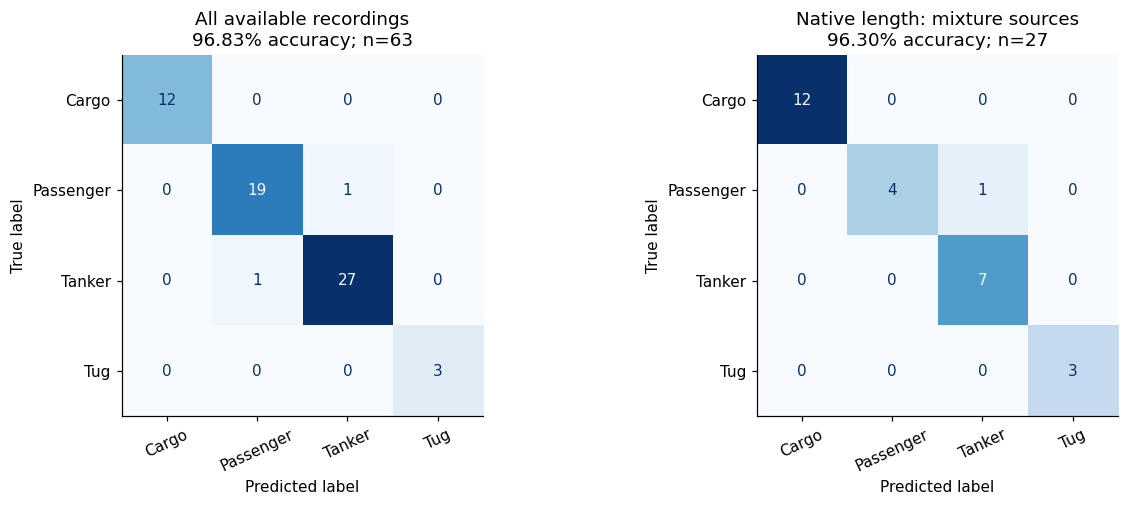

**Unmixed native-length recordings used in the overlap study:**

,recording_id,class,argmax,score_Cargo,score_Passengership,score_Tanker,score_Tug
0,Cargo/103.wav,Cargo,Cargo,0.98579,0.00570,0.00514,0.00007
1,Cargo/110.wav,Cargo,Cargo,0.99020,0.00483,0.01176,0.00040
2,Cargo/15.wav,Cargo,Cargo,0.98918,0.00625,0.00310,0.00141
3,Cargo/27.wav,Cargo,Cargo,0.62100,0.01379,0.00450,0.49807
4,Cargo/38.wav,Cargo,Cargo,0.99681,0.00088,0.00512,0.00029
5,Cargo/41.wav,Cargo,Cargo,0.98732,0.00266,0.00733,0.00032
6,Cargo/44.wav,Cargo,Cargo,0.99338,0.00463,0.00133,0.00143
7,Cargo/62.wav,Cargo,Cargo,0.87053,0.00231,0.18522,0.01031
8,Cargo/69.wav,Cargo,Cargo,0.99689,0.00509,0.00194,0.00027
9,Cargo/78.wav,Cargo,Cargo,0.99442,0.00162,0.00519,0.00128


Original baseline artifacts: [report](results/report.md), [all 63 predictions](results/predictions.csv), [standalone metrics](overlap_results/standalone_baseline_metrics.csv).

In [2]:
# Standalone DeepShip baseline: no mixing, training or model inference repeated.
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

single_root = ROOT / 'dat255_pilot' / 'results'
single_run = json.loads((single_root / 'run.json').read_text())
solo_names = single_run['class_names']
assert single_run['checkpoint_sha256'] == cpu.sha256(ROOT / 'DAT255/models/resnet50-93')
assert single_run['script_sha256'] == cpu.sha256(Path(cpu.__file__))
single_predictions = pd.read_csv(single_root / 'predictions.csv')
assert len(single_predictions) == 63 and single_predictions.recording_id.is_unique
assert set(single_predictions['class']) == set(solo_names)
assert single_predictions.requires_repetition.isin([True, False]).all()
assert all(cpu.sha256(ROOT / 'DeepShip' / row.recording_id) == row.file_sha256
           for row in single_predictions.itertuples())
solo_columns = [f'score_{name}' for name in solo_names]
solo_scores = single_predictions[solo_columns].to_numpy()
assert np.isfinite(solo_scores).all() and ((solo_scores >= 0) & (solo_scores <= 1)).all()
assert np.array_equal(np.array(solo_names)[solo_scores.argmax(axis=1)], single_predictions.argmax)
solo_groups = {
    'All available recordings': single_predictions,
    'Native length: mixture sources': single_predictions[~single_predictions.requires_repetition],
    'Short recordings: repeated': single_predictions[single_predictions.requires_repetition],
}
native_predictions = solo_groups['Native length: mixture sources']
assert len(native_predictions) == 27
# Verify that the native-length baseline is the same cohort and same original
# scores as the saved overlap source baseline, not a different recording split.
mixture_sources = pd.read_csv(RESULTS / 'source_baseline.csv')
assert set(native_predictions.recording_id) == set(mixture_sources.recording_id)
comparison = native_predictions.merge(mixture_sources, on='recording_id', suffixes=('_single', '_overlap'))
for name in solo_names:
    np.testing.assert_allclose(comparison[f'score_{name}'], comparison[f'original_{name}'], atol=1e-5)

standalone_rows, standalone_classes = [], []
for group_name, group in solo_groups.items():
    scores = group[solo_columns].to_numpy()
    predicted = np.array(solo_names)[scores.argmax(axis=1)]
    truth = group['class'].to_numpy()
    targets = np.eye(len(solo_names), dtype=int)[[solo_names.index(label) for label in truth]]
    positives = scores >= 0.5
    standalone_rows.append({
        'Group': group_name, 'Recordings': len(group), 'Correct': int((predicted == truth).sum()),
        'Argmax accuracy': accuracy_score(truth, predicted),
        'Argmax macro-F1': f1_score(truth, predicted, labels=solo_names, average='macro', zero_division=0),
        'Independent macro-F1 @0.5': f1_score(targets, positives, average='macro', zero_division=0),
        'Independent exact match @0.5': accuracy_score(targets, positives),
    })
    if group_name != 'Short recordings: repeated':
        conventional = classification_report(truth, predicted, labels=solo_names,
            output_dict=True, zero_division=0)
        independent = classification_report(targets, positives, target_names=solo_names,
            output_dict=True, zero_division=0)
        for label in solo_names:
            standalone_classes.append({'Group': group_name, 'Class': label,
                **conventional[label], 'Independent recall @0.5': independent[label]['recall'],
                'Independent F1 @0.5': independent[label]['f1-score']})
standalone_summary = pd.DataFrame(standalone_rows).set_index('Group')
standalone_per_class = pd.DataFrame(standalone_classes).set_index(['Group', 'Class'])
display(standalone_summary.round(4))
display(standalone_per_class.round(4))
standalone_summary.to_csv(RESULTS / 'standalone_baseline_metrics.csv')
standalone_per_class.to_csv(RESULTS / 'standalone_baseline_per_class.csv')
print('All recordings: 61/63 correct; native-length mixture sources: 26/27 correct.')
assert standalone_summary.loc['All available recordings', 'Correct'] == 61
assert standalone_summary.loc['Native length: mixture sources', 'Correct'] == 26

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, group_name in zip(axes, ['All available recordings', 'Native length: mixture sources']):
    group = solo_groups[group_name]
    matrix = confusion_matrix(group['class'], group.argmax, labels=solo_names)
    ConfusionMatrixDisplay(matrix, display_labels=['Cargo', 'Passenger', 'Tanker', 'Tug']).plot(
        ax=ax, colorbar=False, cmap='Blues', xticks_rotation=25)
    ax.grid(False)
    accuracy = standalone_summary.loc[group_name, 'Argmax accuracy']
    ax.set_title(f'{group_name}\n{accuracy:.2%} accuracy; n={len(group)}')
savefig('00_standalone_deepship_confusions.png')
display(Markdown('**Unmixed native-length recordings used in the overlap study:**'))
display(native_predictions[['recording_id', 'class', 'argmax'] + solo_columns].round(5))
display(Markdown('Original baseline artifacts: [report](results/report.md), '
                 '[all 63 predictions](results/predictions.csv), '
                 '[standalone metrics](overlap_results/standalone_baseline_metrics.csv).'))

## Design fixed before mixture scoring

Use one deterministic centred 3,007,827-sample window (93.99459375 s, 32 kHz)
from each of the **27 recordings long enough without repetition**. The other
36 recordings are excluded from this experiment rather than cyclically repeated.

| Experiment | Conditions | Reported scenarios |
|---|---|---:|
| Relative level | All 251 cross-class pairs; reference/added AC SIR = -12, -6, 0, +6, +12 dB; full overlap | 1,255 |
| Overlap duration | All 251 pairs; 0, 25, 50, 75, 100% of window; centred addition; active AC SIR = 0 dB | 1,255 |
| Placement sensitivity | First pair of each of six class-pair types, both reference directions; 25, 50, 75%; onset/centre/end | 108 |

The relative-level reference is fixed by recording order. For duration tests,
reference/added roles alternate within each class-pair type. Placement pairs
are selected by filename order, not by their results. Identical conditions share
cached predictions; **2,618 table rows are not 2,618 unique independent mixtures**.

Partial additions use the same centred fragment of source B for a given
duration. That exact fragment is moved for the placement experiment. A 20-ms
half-cosine ramp at its ends reduces artificial switching clicks. Full-overlap
recordings have no added ramp. There is no repetition, shifting of pitch,
time stretching, propagation simulation or synthetic noise generation.

DAT255's original three 460 x 460 channels, FFTs, spectrogram normalisation,
saved ImageNet batch normalisation and float32 CPU inference are retained.
The HF channel sees only about 11.07 seconds centred in the 94-second context.

In [3]:
# This cell performs the experiment if complete results do not already exist.
# Otherwise verify their provenance, then load the actual measured results.
run_path = RESULTS / 'run.json'
cached = json.loads(run_path.read_text()) if run_path.exists() else {}
if cached.get('complete'):
    recipe = json.loads((RESULTS / 'recipe.json').read_text())
    assert recipe['script_sha256'] == cpu.sha256(Path(ex.__file__))
    assert recipe['adapter_sha256'] == cpu.sha256(Path(cpu.__file__))
    assert recipe['checkpoint_sha256'] == cpu.sha256(ROOT / 'DAT255/models/resnet50-93')
    assert all(cpu.sha256(ROOT / 'DeepShip' / name) == digest
               for name, digest in recipe['source_hashes'].items())
    outcomes, summaries = ex.summarize(RESULTS)
    run = cached
    print('Loaded completed, hash-verified CPU measurements; no inference repeated.')
else:
    outcomes, summaries, run = ex.run(RESULTS, threads=8)
assert run['complete'], 'A partial run cannot be reported as the completed study.'
names = json.loads((RESULTS / 'recipe.json').read_text())['class_names']

baseline = pd.read_csv(RESULTS / 'source_baseline.csv')
level = summaries['level'].sort_values('sir_db')
duration = summaries['duration'].sort_values('fraction')
placement = summaries['placement']
pair_summary = pd.read_csv(RESULTS / 'summary_class_pairs.csv')
display(pd.Series({k: run[k] for k in ['n_source_recordings', 'n_cross_class_pairs',
    'n_scenarios', 'cached_forward_passes', 'undefined_control_cache_entries',
    'initial_run_elapsed_seconds', 'peak_rss_gib', 'audio_cache_mib']}, name='Measured execution'))

Loaded completed, hash-verified CPU measurements; no inference repeated.


n_source_recordings                  27.000000
n_cross_class_pairs                 251.000000
n_scenarios                        2618.000000
cached_forward_passes              7251.000000
undefined_control_cache_entries      24.000000
initial_run_elapsed_seconds        2072.222844
peak_rss_gib                          1.229141
audio_cache_mib                     309.796635
Name: Measured execution, dtype: float64

## Mixing and controls

DeepShip's large DC offsets would dominate ordinary RMS. Define each source's
acoustic-component RMS as `sqrt(mean((x - mean(x))**2))`, and form
`u = x / acoustic_RMS`. **The mean is retained in the actual classifier input**;
mean subtraction is used to measure levels only.

A single global headroom factor `h`, fixed before scoring any mixture, bounds
every waveform/control below 0.90 full scale. The same factor is used everywhere:

```text
A = h * u_A
B = h * gain_B * placed_fragment(u_B) * envelope
mixture = A + B
matched solos = A, B
DC-only control for A = A + h * gain_B * mean(B_fragment_before_scaling) * envelope
DC-only control for B = B + h * mean(u_A)
```

For full overlaps `gain_B = 10**(-SIR_dB/20)` because each source has unit AC
RMS. For partial overlaps its gain is adjusted to achieve the specified SIR
**during the active overlap interval**, including the fade's effect on B's AC
energy. Thus a shorter addition is not automatically louder to preserve its
whole-window energy. The achieved SIR is recorded for every scenario.

These are recording-level ratios: each source also contains its original
background noise. They are not calibrated isolated-vessel power ratios.
DC-only comparisons are controlled contrasts along a specified perturbation
path, not a unique causal decomposition of a nonlinear network.

In [4]:
baseline_table = baseline.groupby('class').agg(
    recordings=('recording_id', 'size'),
    median_ac_rms=('ac_rms', 'median'),
    median_dc_energy_fraction=('dc_energy_fraction', 'median'))

baseline_table['original_argmax_recall'] = baseline.assign(
    correct=baseline.original_argmax == baseline['class']).groupby('class').correct.mean()

baseline_table['scaled_argmax_recall'] = baseline.assign(
    correct=baseline.scaled_argmax == baseline['class']).groupby('class').correct.mean()

base_scores = baseline[[f'scaled_{name}' for name in names]].to_numpy()
own_indices = np.array([names.index(name) for name in baseline['class']])
own_positive = base_scores[np.arange(len(baseline)), own_indices] >= .5
baseline_table['threshold_recall_at_0_5'] = baseline.assign(detected=own_positive).groupby('class').detected.mean()

baseline_table['mean_other_positive_labels'] = baseline.assign(
    other=(base_scores >= .5).sum(axis=1) - own_positive.astype(int)).groupby('class').other.mean()

display(baseline_table.round(5))
print(f"Original accuracy: {run['original_argmax_accuracy']:.3%}")
print(f"Gain-control accuracy: {run['gain_matched_argmax_accuracy']:.3%}")
print(f"Largest score change from gain normalisation alone: {run['max_score_change_from_common_gain']:.8f}")
display(baseline[['recording_id', 'vessel_name', 'vessel_identity_status', 'window_start_sample_32k',
                  'original_argmax', 'scaled_argmax']])

,recordings,median_ac_rms,median_dc_energy_fraction,original_argmax_recall,scaled_argmax_recall,threshold_recall_at_0_5,mean_other_positive_labels
class,,,,,,,
Cargo,12,0.00559,0.96394,1.0,1.0,1.0,0.0
Passengership,5,0.00507,0.97212,0.8,0.8,0.8,0.0
Tanker,7,0.00509,0.97158,1.0,1.0,1.0,0.0
Tug,3,0.00414,0.98093,1.0,1.0,1.0,0.0


Original accuracy: 96.296%
Gain-control accuracy: 96.296%
Largest score change from gain normalisation alone: 0.00000843


,recording_id,vessel_name,vessel_identity_status,window_start_sample_32k,original_argmax,scaled_argmax
0,Cargo/103.wav,SEASPAN SWIFT,name only; no verified MMSI/IMO,1680086,Cargo,Cargo
1,Cargo/110.wav,SEASPAN SWIFT,name only; no verified MMSI/IMO,1728086,Cargo,Cargo
2,Cargo/15.wav,NEW NADA,name only; no verified MMSI/IMO,1488086,Cargo,Cargo
3,Cargo/27.wav,SEASPAN RELIANT,name only; no verified MMSI/IMO,1632086,Cargo,Cargo
4,Cargo/38.wav,ARIES LEADER,name only; no verified MMSI/IMO,1632086,Cargo,Cargo
5,Cargo/41.wav,PRINCESS SUPERIOR,name only; no verified MMSI/IMO,1424086,Cargo,Cargo
6,Cargo/44.wav,WESTWOOD COLUMBIA,name only; no verified MMSI/IMO,1696086,Cargo,Cargo
7,Cargo/62.wav,ANASTASIA,name only; no verified MMSI/IMO,1664086,Cargo,Cargo
8,Cargo/69.wav,PRINCESS SUPERIOR,name only; no verified MMSI/IMO,1440086,Cargo,Cargo
9,Cargo/78.wav,CMA CGM,name only; no verified MMSI/IMO,1600086,Cargo,Cargo


## Endpoints and denominators

Four sigmoid scores are retained before applying the fixed **0.5** threshold.
No threshold is fitted to these mixtures. Argmax is used only to describe the
single-source baseline; a two-class mixture has two expected positive labels.

* **All-present recall:** every expected class is detected, allowing extra false positives.
* **Exact match:** all expected classes and no absent classes are detected.
* **Macro-F1:** equal weight to the four class F1 scores, not label-wise binary accuracy.
* **Source retention:** among matched solos detected correctly, the fraction still detected in the mixture.
* **Score change:** mixture own-class score minus its matched-solo score.
* **DC-adjusted contrast:** mixture own-class score minus its DC-only-control score.

At **0% overlap B is absent**: there is one true label, and B retention is
undefined. Full-source-conditional results use sources whose own-class scores
reach 0.5 in their complete isolated windows; other positive labels do not
determine this selection. Matched-solo-conditional results additionally
account for loss caused by shortening/masking the added source itself. Their
changing denominators are reported, rather than silently discarding failures.

,n_scenarios,all_present_recall,exact_match,macro_f1,retention_a,retention_b,mean_absent_false_positives
sir_db,,,,,,,
-12,251,0.0040,0.0040,0.6218,0.0581,0.9079,0.0319
-6,251,0.0279,0.0279,0.6018,0.1992,0.7364,0.0797
0,251,0.0199,0.0199,0.5423,0.4481,0.4226,0.0677
6,251,0.0040,0.0040,0.4900,0.7593,0.1506,0.0359
12,251,0.0120,0.0120,0.4763,0.9295,0.0460,0.0199


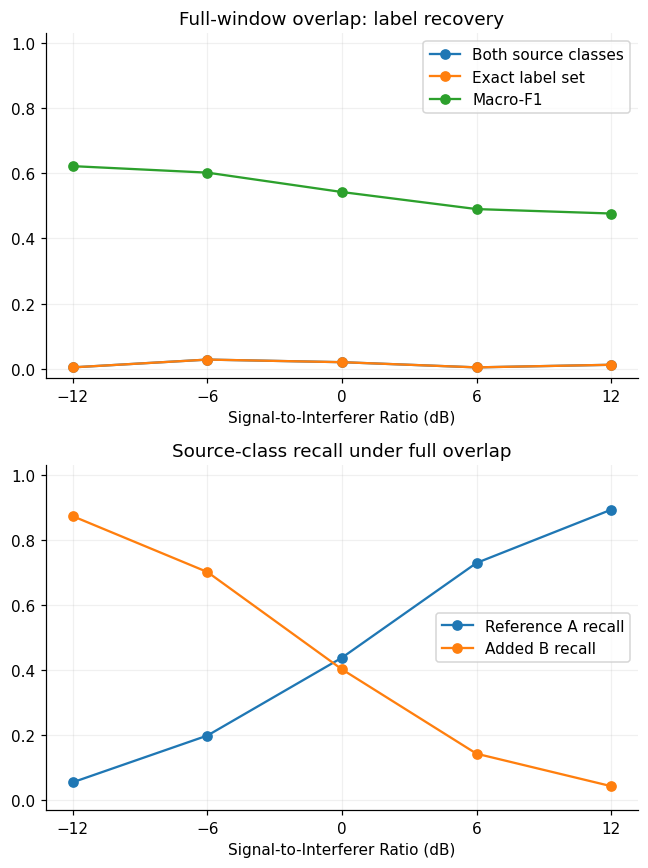

In [5]:
columns = ['n_scenarios', 'all_present_recall', 'exact_match', 'macro_f1',
           'retention_a', 'retention_b', 'mean_absent_false_positives']

display(level.set_index('sir_db')[columns].round(4))

fig, axes = plt.subplots(2, 1, figsize=(6, 8))
for col, label in [('all_present_recall', 'Both source classes'), ('exact_match', 'Exact label set'), ('macro_f1', 'Macro-F1')]:
    axes[0].plot(level.sir_db, level[col], 'o-', label=label)
for col, label in [('recall_a', 'Reference A recall'), ('recall_b', 'Added B recall')]:
    axes[1].plot(level.sir_db, level[col], 'o-', label=label)
for ax in axes:
    ax.set(xlabel='Signal-to-Interferer Ratio (dB)', ylim=(-.03, 1.03), xticks=list(ex.RATIOS))
    ax.legend()
    
axes[0].set_title('Full-window overlap: label recovery')
axes[1].set_title('Source-class recall under full overlap')
savefig('01_relative_levels.png')

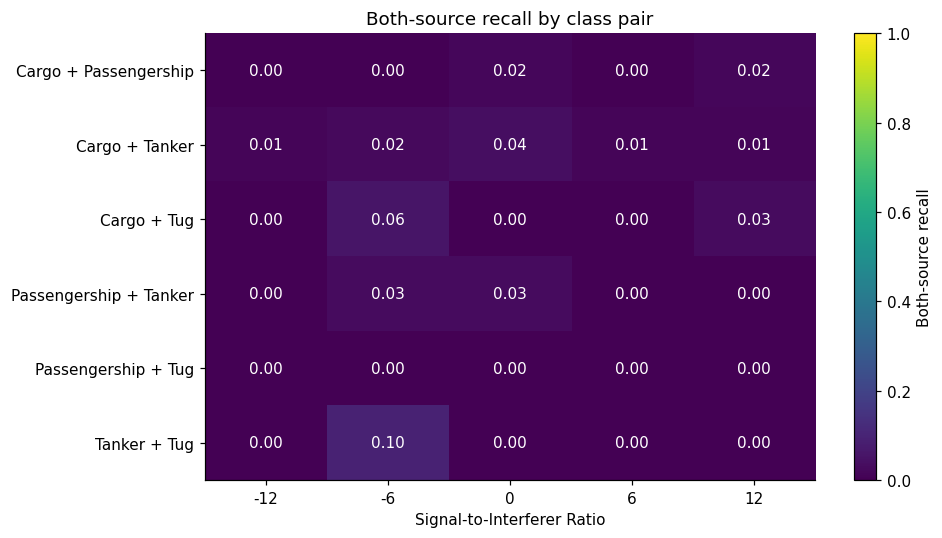

,all_present_recall_pooled,exact_match_pooled,all_present_recall_equal_pair_type,exact_match_equal_pair_type
sir_db,,,,
-12,0.0040,0.0040,0.0020,0.0020
-6,0.0279,0.0279,0.0339,0.0339
0,0.0199,0.0199,0.0135,0.0135
6,0.0040,0.0040,0.0020,0.0020
12,0.0120,0.0120,0.0094,0.0094


In [6]:
heat = pair_summary[pair_summary.family == 'level'].pivot(
    index='pair_class', columns='sir_db', values='all_present_recall').reindex(columns=list(ex.RATIOS))
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heat, vmin=0, vmax=1, cmap='viridis', aspect='auto')
ax.grid(False)
ax.set(xticks=range(len(heat.columns)), xticklabels=heat.columns,
       yticks=range(len(heat)), yticklabels=heat.index,
       xlabel='Signal-to-Interferer Ratio', title='Both-source recall by class pair')
for i in range(len(heat)):
    for j in range(len(heat.columns)):
        ax.text(j, i, f'{heat.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if heat.iloc[i, j] < .55 else 'black')
fig.colorbar(im, ax=ax, label='Both-source recall')
savefig('02_class_pair_heatmap.png')
pooled = level.set_index('sir_db')[['all_present_recall', 'exact_match']]
macro_pair = pd.read_csv(RESULTS / 'macro_pair_level.csv', index_col='sir_db')
display(pooled.join(macro_pair[['all_present_recall', 'exact_match']], lsuffix='_pooled', rsuffix='_equal_pair_type').round(4))

Unequal class counts produce unequal pair counts (for example 84 cargo–tanker
pairs but only 15 passenger–tug pairs). The table above therefore also weights
the six class-pair types equally. Neither weighting makes reused sources
independent; both are descriptive views of this finite source collection.
In the full-level experiment A is the earlier filename-ordered source, so
A/B curves also reflect this class ordering. The symmetric SIR sweep reverses
which recording is stronger; class-pair stratification is essential before
attributing an A/B difference to relative level alone.

### Exploratory ranking check

A fixed 0.5 presence threshold can fail even when the two source classes rank
first and second. The following threshold-free diagnostic distinguishes those
cases: **top-two recovery** requires exactly the two known source classes in
the two highest scores. **Top-one present** asks whether the highest score is
either source class; it does not establish detection of both sources or correct
identification of the stronger source. Neither diagnostic replaces the fixed
threshold endpoints. Rows with no added source are excluded from this check.

,,scenarios,top_two_recovery,top_one_present
sir_db,fraction,,,
-12,1.0,251,0.4582,0.9562
-6,1.0,251,0.5259,0.9004
0,1.0,251,0.6255,0.8884
6,1.0,251,0.5498,0.9402
12,1.0,251,0.4343,0.9721


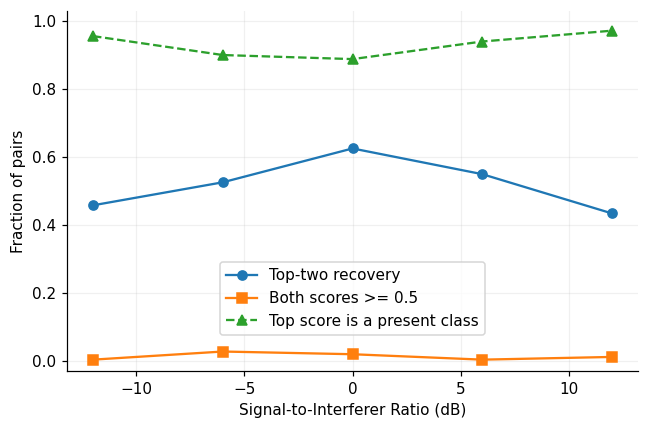

In [7]:
ranking = outcomes[outcomes.fraction > 0].copy()
order = np.argsort(ranking[[f'mixture_{name}' for name in names]].to_numpy(), axis=1)
ranking['top_two_recovery'] = [set(np.array(names)[indices[-2:]]) == {a, b}
    for indices, a, b in zip(order, ranking.class_a, ranking.class_b)]
ranking['top_one_present'] = [names[indices[-1]] in (a, b)
    for indices, a, b in zip(order, ranking.class_a, ranking.class_b)]
ranking_summary = ranking.groupby(['family', 'sir_db', 'fraction']).agg(
    scenarios=('scenario_id', 'size'), top_two_recovery=('top_two_recovery', 'mean'),
    top_one_present=('top_one_present', 'mean'))
ranking_summary.to_csv(RESULTS / 'threshold_free_summary.csv')
display(ranking_summary.loc['level'].round(4))
ranked_level = ranking_summary.loc['level'].reset_index().sort_values('sir_db')
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ranked_level.sir_db, ranked_level.top_two_recovery, 'o-', label='Top-two recovery')
ax.plot(level.sir_db, level.all_present_recall, 's-', label='Both scores >= 0.5')
ax.plot(ranked_level.sir_db, ranked_level.top_one_present, '^--', label='Top score is a present class')
ax.set(xlabel='Signal-to-Interferer Ratio (dB)', ylabel='Fraction of pairs',
       ylim=(-.03, 1.03)) #, title='Ranking information versus simultaneous threshold detection')
ax.legend(loc='lower center', bbox_to_anchor=(.5, .08))
savefig('08_ranking_diagnostic.png')

,n_scenarios,all_present_recall,exact_match,macro_f1,retention_a,retention_b,mean_absent_false_positives,matched_control_coverage_b,n_both_full_source_detected,both_recall_full_source_conditional
fraction,,,,,,,,,,
0.00,251,0.9522,0.9522,0.9700,1.0000,NaN,0.0000,NaN,0,NaN
0.25,251,0.0000,0.0000,0.6121,0.8787,NaN,0.0398,1.0,229,0.0000
0.50,251,0.0000,0.0000,0.5408,0.7238,NaN,0.0717,1.0,229,0.0000
0.75,251,0.0040,0.0040,0.4999,0.5816,NaN,0.0717,1.0,229,0.0044
1.00,251,0.0199,0.0199,0.5423,0.4477,0.4232,0.0677,1.0,229,0.0218


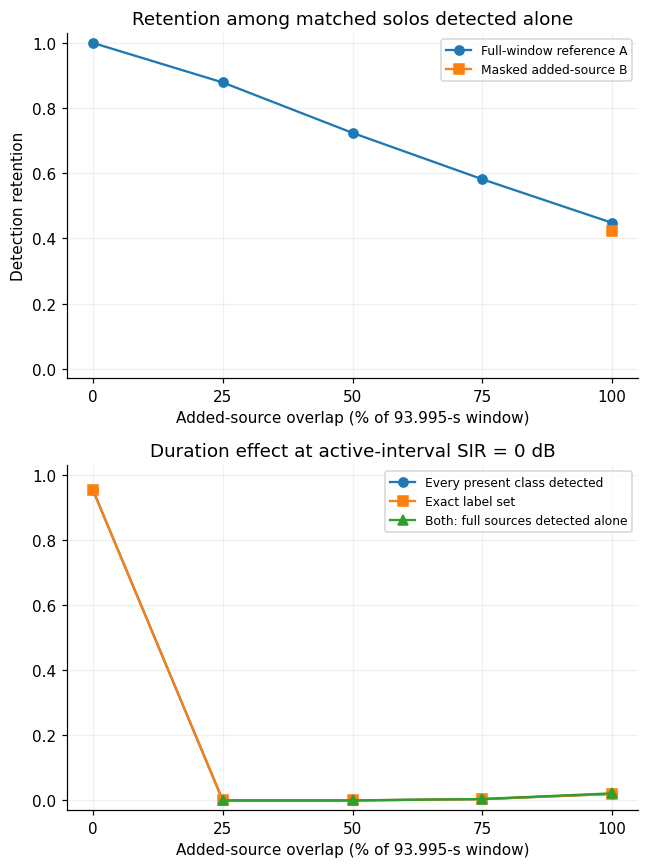

,reference_solo_detection,added_matched_solo_detection,added_solo_max_own_score
fraction,,,
0.00,0.9522,NaN,NaN
0.25,0.9522,0.0000,0.1593
0.50,0.9522,0.0000,0.1249
0.75,0.9522,0.0000,0.0955
1.00,0.9522,0.9602,0.9987


**Context-loss control:** the partial-window B-only inputs in this run never reach their true-class threshold at 25%, 50% or 75% duration. Their matched retention is therefore undefined, rather than zero. Added-source failures cannot all be attributed to A masking B. The full-window reference A retains its clean input context, making its paired retention curve the clearest duration-overlap endpoint.

In [8]:
display(duration.set_index('fraction')[columns + ['matched_control_coverage_b',
    'n_both_full_source_detected', 'both_recall_full_source_conditional']].round(4))
fig, axes = plt.subplots(2, 1, figsize=(6, 8))
axes[0].plot(duration.fraction * 100, duration.retention_a, 'o-', label='Full-window reference A')
axes[0].plot(duration.fraction * 100, duration.retention_b, 's-', label='Masked added-source B')
axes[0].set(title='Retention among matched solos detected alone', ylabel='Detection retention')
axes[1].plot(duration.fraction * 100, duration.all_present_recall, 'o-', label='Every present class detected')
axes[1].plot(duration.fraction * 100, duration.exact_match, 's-', label='Exact label set')
axes[1].plot(duration.fraction * 100, duration.both_recall_full_source_conditional, '^-', label='Both: full sources detected alone')
axes[1].set_title('Duration effect at active-interval SIR = 0 dB')
for ax in axes:
    ax.set(xlabel='Added-source overlap (% of 93.995-s window)', ylim=(-.03, 1.03), xticks=[0, 25, 50, 75, 100])
    ax.legend(fontsize=8)
savefig('03_overlap_duration.png')
duration_controls = outcomes[outcomes.family == 'duration'].groupby('fraction').agg(
    reference_solo_detection=('clean_detected_a', 'mean'),
    added_matched_solo_detection=('clean_detected_b', 'mean'),
    added_solo_max_own_score=('solo_b_own_b', 'max'))
duration_controls.loc[0, 'added_matched_solo_detection'] = np.nan  # B is absent.
display(duration_controls.round(4))
if (duration_controls.loc[[.25, .5, .75], 'added_matched_solo_detection'] == 0).all():
    display(Markdown('**Context-loss control:** the partial-window B-only inputs in this run '
        'never reach their true-class threshold at 25%, 50% or 75% duration. Their matched '
        'retention is therefore undefined, rather than zero. Added-source failures cannot '
        'all be attributed to A masking B. The full-window reference A retains its clean '
        'input context, making its paired retention curve the clearest duration-overlap endpoint.'))

,n_scenarios,n_both_clean_detected,both_recall_conditional,n_both_full_source_detected,both_recall_full_source_conditional
sir_db,,,,,
-12,251,229,0.0044,229,0.0044
-6,251,229,0.0306,229,0.0306
0,251,229,0.0218,229,0.0218
6,251,229,0.0044,229,0.0044
12,251,229,0.0131,229,0.0131


,n_scenarios,n_both_clean_detected,both_recall_conditional,n_both_full_source_detected,both_recall_full_source_conditional
fraction,,,,,
0.00,251,0,NaN,0,NaN
0.25,251,0,NaN,229,0.0000
0.50,251,0,NaN,229,0.0000
0.75,251,0,NaN,229,0.0044
1.00,251,229,0.0218,229,0.0218


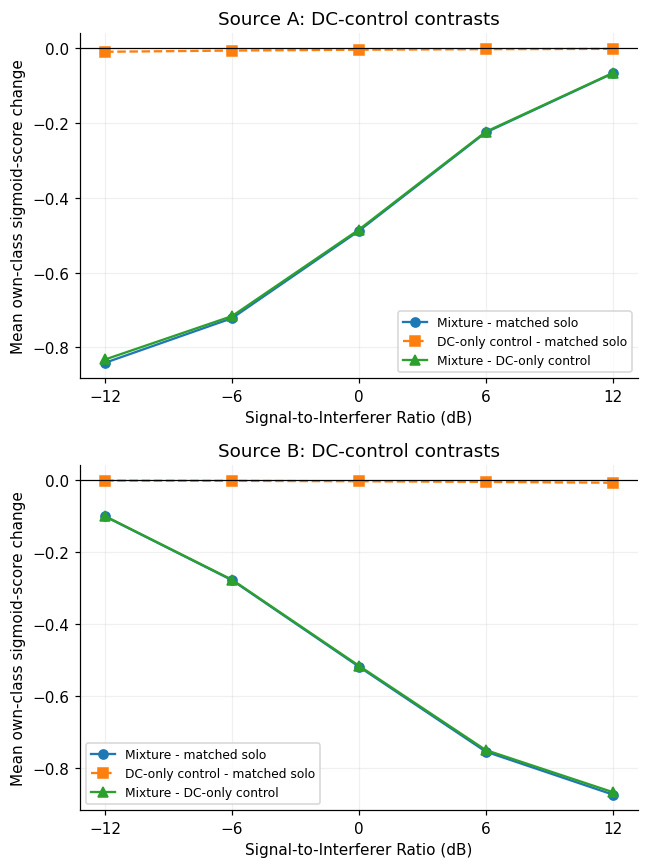

,mean_absolute_DC_only_change,p95_absolute_DC_only_change,maximum_absolute_DC_only_change
Reference A,0.00333,0.01686,0.04234
Added B,0.00259,0.01442,0.03461


In [9]:
conditional_columns = ['n_scenarios', 'n_both_clean_detected', 'both_recall_conditional',
                       'n_both_full_source_detected', 'both_recall_full_source_conditional']

display(level.set_index('sir_db')[conditional_columns].round(4))
display(duration.set_index('fraction')[conditional_columns].round(4))

fig, axes = plt.subplots(2, 1, figsize=(6, 8))
for role, ax in zip(('a', 'b'), axes):
    ax.plot(level.sir_db, level[f'score_change_{role}'], 'o-', label='Mixture - matched solo')
    ax.plot(level.sir_db, level[f'dc_only_change_{role}'], 's--', label='DC-only control - matched solo')
    ax.plot(level.sir_db, level[f'dc_adjusted_change_{role}'], '^-', label='Mixture - DC-only control')
    ax.axhline(0, color='black', lw=.8)
    ax.set(xlabel='Signal-to-Interferer Ratio (dB)', ylabel='Mean own-class sigmoid-score change',
           title=f"Source {role.upper()}: DC-control contrasts", xticks=list(ex.RATIOS))
    ax.legend(fontsize=8)
savefig('04_dc_controls.png')

equal_controls = outcomes[(outcomes.family == 'level') & (outcomes.sir_db == 0)]
display(pd.DataFrame({
    'mean_absolute_DC_only_change': [equal_controls[f'dc_only_change_{r}'].abs().mean() for r in ['a', 'b']],
    'p95_absolute_DC_only_change': [equal_controls[f'dc_only_change_{r}'].abs().quantile(.95) for r in ['a', 'b']],
    'maximum_absolute_DC_only_change': [equal_controls[f'dc_only_change_{r}'].abs().max() for r in ['a', 'b']]
}, index=['Reference A', 'Added B']).round(5))

## Placement, HF coverage and undefined controls

At 25% duration, onset/end additions lie outside the centred HF view. Their
**B-only masked control has a silent HF spectrogram**, for which DAT255's
original log/std normalisation is undefined. Those control scores are explicitly
missing, not treated as failed detections and not repaired with invented noise.
The corresponding mixtures remain valid because full-window A is present.
Moving B also changes which segment of A it overlaps. These are placement
sensitivity checks; a placement difference alone does not uniquely establish
that the HF crop caused that difference.

Unconditional mixture recall and full-source-conditional recall remain usable.
Matched B-solo retention is available only when that control is defined and
detected. DC-only B controls can also be undefined; their missing contrasts
are excluded from their mean. Read coverage and cache-status counts alongside
these results. This is a restriction of the trained representation, not a
reason to change its normalisation during the primary experiment.

n_scenarios  recall_a  recall_b  retention_a  retention_b  \
fraction position                                                              
0.25     centre             12    0.5833    0.0833       0.7778          NaN   
         end                12    0.7500    0.0833       1.0000          NaN   
         onset              12    0.7500    0.0000       1.0000          NaN   
0.50     centre             12    0.4167    0.3333       0.5556          NaN   
         end                12    0.5000    0.1667       0.6667          NaN   
         onset              12    0.5833    0.3333       0.6667          NaN   
0.75     centre             12    0.3333    0.3333       0.4444          NaN   
         end                12    0.2500    0.3333       0.3333          NaN   
         onset              12    0.4167    0.3333       0.4444          NaN   

                   matched_control_coverage_b  \
fraction position                               
0.25     centre                           1.0   
         end                              0.0   
         onset                            0.0   
0.50     centre                           1.0   
         end                              1.0   
         onset                            1.0   
0.75     centre                           1.0   
         end                              1.0   
         onset                            1.0   

                   both_recall_full_source_conditional  
fraction position                                       
0.25     centre                                    0.0  
         end                                       0.0  
         onset                                     0.0  
0.50     centre                                    0.0  
         end                                       0.0  
         onset                                     0.0  
0.75     centre                                    0.0  
         end                                       0.0  
         onset                                     0.0

scenarios  mean_hf_coverage
fraction position                             
0.25     centre           12          1.000000
         end              12          0.000000
         onset            12          0.000000
0.50     centre           12          1.000000
         end              12          0.500000
         onset            12          0.500003
0.75     centre           12          1.000000
         end              12          1.000000
         onset            12          1.000000

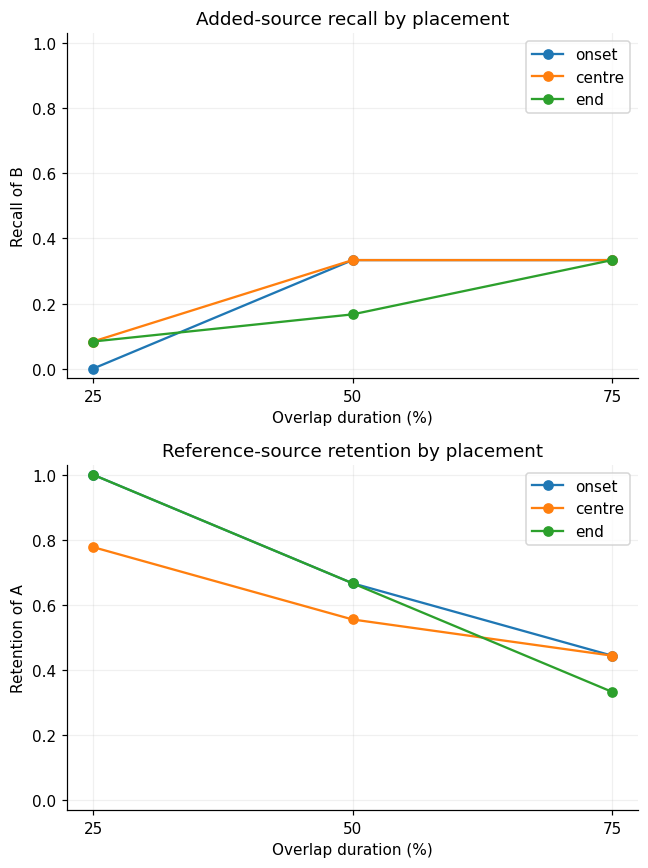

input_kind   status                              
dc_a         ok                                      2098
dc_b         ok                                      2098
masked_solo  ok                                       819
             undefined_silent_spectrogram_control      24
mixture      ok                                      2098
original     ok                                        27
solo         ok                                        87
Name: Prediction-cache entries, dtype: int64

In [10]:
display(placement.set_index(['fraction', 'position'])[
    ['n_scenarios', 'recall_a', 'recall_b', 'retention_a', 'retention_b',
     'matched_control_coverage_b', 'both_recall_full_source_conditional']].round(4))
observed = outcomes[outcomes.family == 'placement']

display(observed.groupby(['fraction', 'position']).agg(
    scenarios=('scenario_id', 'size'), mean_hf_coverage=('hf_overlap_fraction', 'mean')))

fig, axes = plt.subplots(2, 1, figsize=(6, 8))
for position in ['onset', 'centre', 'end']:
    part = placement[placement.position == position].sort_values('fraction')
    axes[0].plot(part.fraction * 100, part.recall_b, 'o-', label=position)
    axes[1].plot(part.fraction * 100, part.retention_a, 'o-', label=position)
axes[0].set(title='Added-source recall by placement', ylabel='Recall of B')
axes[1].set(title='Reference-source retention by placement', ylabel='Retention of A')
for ax in axes:
    ax.set(xlabel='Overlap duration (%)', xticks=[25, 50, 75], ylim=(-.03, 1.03))
    ax.legend()
savefig('05_placement.png')

cache = pd.read_csv(RESULTS / 'prediction_cache.csv')
cache['input_kind'] = cache.key.map(lambda key: json.loads(key)[0])
display(cache.groupby(['input_kind', 'status']).size().rename('Prediction-cache entries'))

## Effects by original source recording

Below, each recording contributes one row, aggregating its 0-dB full-overlap
partners across both roles. These are descriptive per-recording effects;
the partners are reused across rows. Vessel names are metadata strings and
sometimes ambiguous. Three tug recordings remain three source recordings.

In [11]:
zero = outcomes[(outcomes.family == 'level') & (outcomes.sir_db == 0)]
source_rows = []
for role in ['a', 'b']:
    for _, row in zero.iterrows():
        source_rows.append({'recording_id': row[f'source_{role}'], 'class': row[f'class_{role}'],
            'clean_detected': row[f'clean_detected_{role}'], 'mixture_detected': row[f'detected_{role}'],
            'score_change': row[f'score_change_{role}'], 'dc_adjusted_change': row[f'dc_adjusted_change_{role}']})
per_source = pd.DataFrame(source_rows).groupby(['class', 'recording_id']).agg(
    partner_recordings=('mixture_detected', 'size'), clean_detection=('clean_detected', 'mean'),
    mixture_detection_rate=('mixture_detected', 'mean'), mean_score_change=('score_change', 'mean'),
    mean_dc_adjusted_change=('dc_adjusted_change', 'mean'))
display(per_source.round(4))
per_source.to_csv(RESULTS / 'per_source_0db.csv')

partner_recordings  clean_detection  \
class         recording_id                                                
Cargo         Cargo/103.wav                         15              1.0   
              Cargo/110.wav                         15              1.0   
              Cargo/15.wav                          15              1.0   
              Cargo/27.wav                          15              1.0   
              Cargo/38.wav                          15              1.0   
              Cargo/41.wav                          15              1.0   
              Cargo/44.wav                          15              1.0   
              Cargo/62.wav                          15              1.0   
              Cargo/69.wav                          15              1.0   
              Cargo/78.wav                          15              1.0   
              Cargo/96.wav                          15              1.0   
              Cargo/99.wav                          15              1.0   
Passengership Passengership/23.wav                  22              0.0   
              Passengership/33.wav                  22              1.0   
              Passengership/37.wav                  22              1.0   
              Passengership/4.wav                   22              1.0   
              Passengership/50.wav                  22              1.0   
Tanker        Tanker/13.wav                         20              1.0   
              Tanker/2.wav                          20              1.0   
              Tanker/20.wav                         20              1.0   
              Tanker/29.wav                         20              1.0   
              Tanker/38.wav                         20              1.0   
              Tanker/39.wav                         20              1.0   
              Tanker/6.wav                          20              1.0   
Tug           Tug/40.wav                            24              1.0   
              Tug/49.wav                            24              1.0   
              Tug/9.wav                             24              1.0   

                                    mixture_detection_rate  mean_score_change  \
class         recording_id                                                      
Cargo         Cargo/103.wav                         0.4667            -0.5779   
              Cargo/110.wav                         0.2000            -0.7005   
              Cargo/15.wav                          0.1333            -0.8613   
              Cargo/27.wav                          0.3333            -0.2890   
              Cargo/38.wav                          0.3333            -0.6152   
              Cargo/41.wav                          0.7333            -0.2935   
              Cargo/44.wav                          0.6667            -0.3358   
              Cargo/62.wav                          0.2667            -0.5932   
              Cargo/69.wav                          0.7333            -0.3027   
              Cargo/78.wav                          0.1333            -0.7933   
              Cargo/96.wav                          0.6667            -0.3341   
              Cargo/99.wav                          0.0667            -0.8596   
Passengership Passengership/23.wav                  0.0909            -0.0860   
              Passengership/33.wav                  0.5909            -0.4599   
              Passengership/37.wav                  0.8182            -0.2499   
              Passengership/4.wav                   0.6364            -0.4051   
              Passengership/50.wav                  0.1818            -0.6445   
Tanker        Tanker/13.wav                         0.8500            -0.1757   
              Tanker/2.wav                          0.2000            -0.5169   
              Tanker/20.wav                         0.7000            -0.3095   
              Tanker/29.wav                         0.8500            -0.2190 

## Inspect generated signals and the actual spectrogram representation

The example pair below is the first filename-ordered cargo/passenger pair,
selected before scoring. Nine representative full-length synthetic WAVs are
saved in `overlap_results/examples/`; all other mixtures can be regenerated
exactly from the source IDs, offsets, gains and recipe without storing them.

,scenario_id,family,a,b,sir_db,fraction,position,path
0,scene_00002,level,0,12,0,1.00,centre,examples/scene_00002.wav
1,scene_00052,level,0,17,0,1.00,centre,examples/scene_00052.wav
2,scene_00122,level,0,24,0,1.00,centre,examples/scene_00122.wav
3,scene_01802,level,12,17,0,1.00,centre,examples/scene_01802.wav
4,scene_01872,level,12,24,0,1.00,centre,examples/scene_01872.wav
5,scene_02302,level,17,24,0,1.00,centre,examples/scene_02302.wav
6,scene_00006,duration,0,12,0,0.25,centre,examples/scene_00006.wav
7,scene_00007,duration,0,12,0,0.50,centre,examples/scene_00007.wav
8,scene_00008,duration,0,12,0,0.75,centre,examples/scene_00008.wav


Example: Cargo/103.wav + Passengership/23.wav | SIR: 0 dB


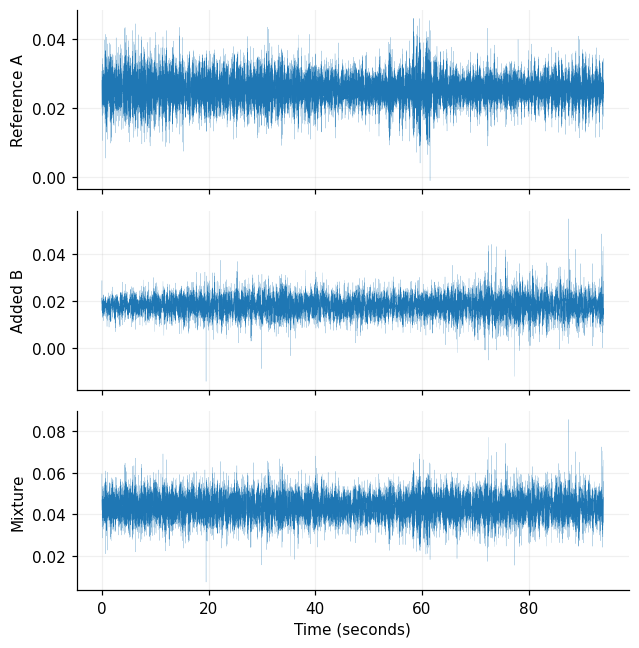

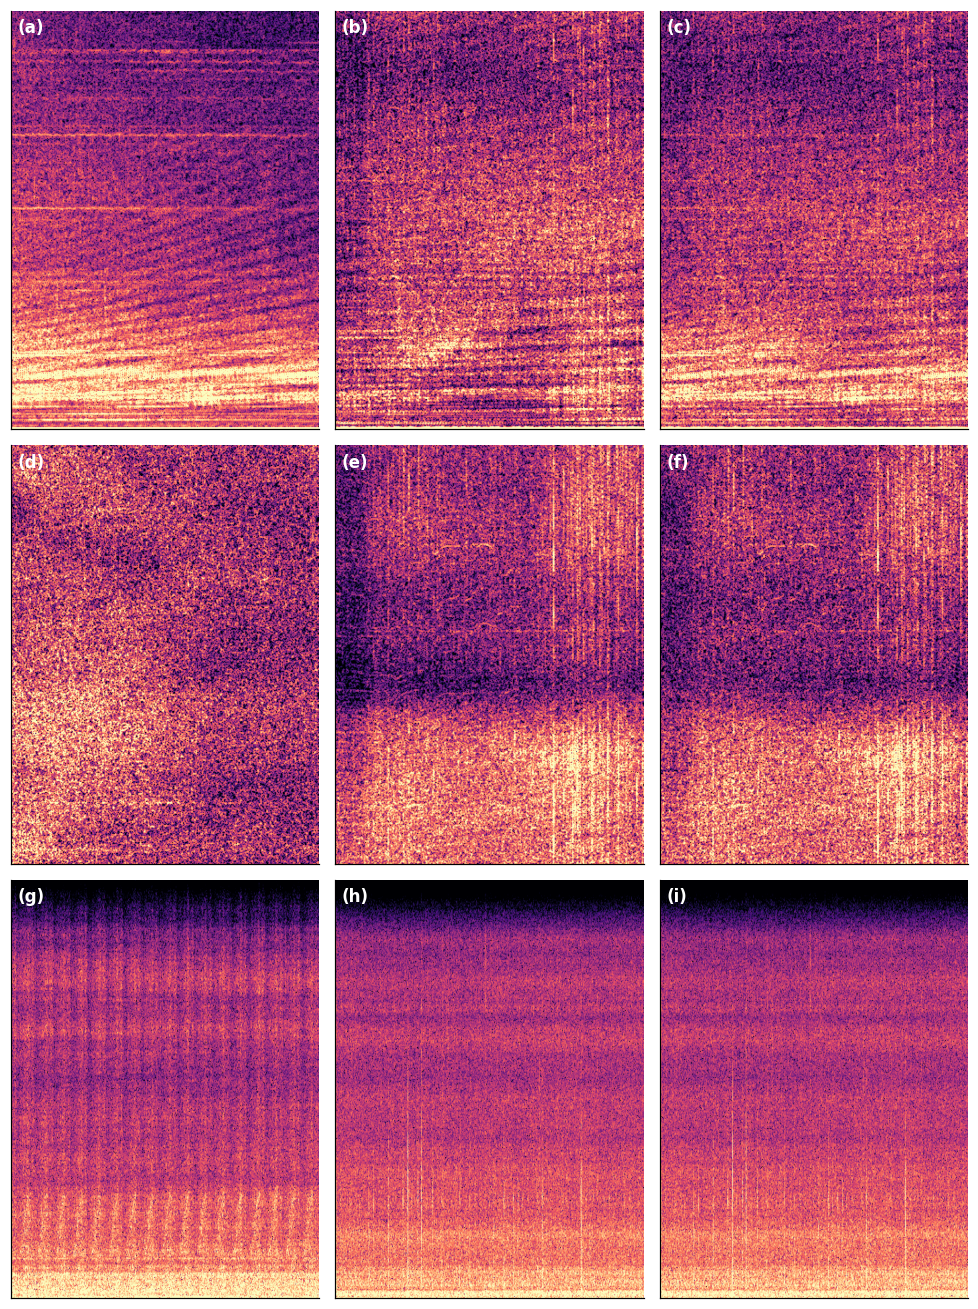

In [12]:

# Load example manifest and select a representative level-mixture scenario
examples = pd.read_csv(RESULTS / 'examples/manifest.csv')
display(examples[['scenario_id', 'family', 'a', 'b', 'sir_db', 'fraction', 'position', 'path']])
chosen_id = examples[examples.family == 'level'].iloc[0].scenario_id
scene = outcomes[outcomes.scenario_id == chosen_id].iloc[0]
source_lookup = baseline.set_index('recording_id')

# Load and gain-match both source recordings using their RMS levels
a_raw, _ = cpu.read_window(ROOT / 'DeepShip' / scene.source_a)
b_raw, _ = cpu.read_window(ROOT / 'DeepShip' / scene.source_b)
h = float(json.loads((RESULTS / 'recipe.json').read_text())['headroom'])
a_signal = h * a_raw / source_lookup.loc[scene.source_a, 'ac_rms']
b_signal = h * scene.gain_b * ex.place_fragment(
    b_raw / source_lookup.loc[scene.source_b, 'ac_rms'], scene.fraction, scene.position)
mix_signal = a_signal + b_signal

# Verify the reconstructed mixture matches the saved example
saved, _ = sf.read(RESULTS / examples[examples.scenario_id == chosen_id].iloc[0].path, dtype='float32')
assert np.max(np.abs(saved - mix_signal[0].numpy())) < 1e-6
print('Example:', scene.source_a, '+', scene.source_b, '| SIR:', scene.sir_db, 'dB')
signals = {'Reference A': a_signal, 'Added B': b_signal, 'Mixture': mix_signal}

# Plot the three gain-matched waveforms
fig, axes = plt.subplots(3, 1, figsize=(6, 6), sharex=True)
stride = 256
for ax, (label, signal) in zip(axes, signals.items()):
    ax.plot(np.arange(0, signal.shape[1], stride) / cpu.SAMPLE_RATE, signal[0, ::stride].numpy(), lw=.1)
    ax.set_ylabel(label)
# axes[0].set_title('Actual gain-matched model input waveforms (DC retained)')
axes[-1].set_xlabel('Time (seconds)')
savefig('06_example_waveforms.png')

# Generate the three-channel spectrograms for each source and mixture
fig, axes = plt.subplots(3, 3, figsize=(9, 12))
bands = ['LF: approx. 0–449 Hz', 'LF: approx. 449–898 Hz', 'HF: approx. 375–14,719 Hz']
letters = list('abcdefghi')
with torch.inference_mode():
    for col, (label, signal) in enumerate(signals.items()):
        spec = cpu.wavToSpecs(signal, (cpu.WINDOW_SAMPLES - cpu.HF_SAMPLES) // 2).numpy()
        for channel in range(3):
            ax = axes[channel, col]
            ax.imshow(spec[channel], origin='lower', aspect='auto', vmin=0, vmax=1, cmap='magma')
            ax.grid(False)
            ax.set_xticks([])
            ax.set_yticks([])
            # Label subplots sequentially from (a) to (i)
            idx = channel * 3 + col
            ax.text(0.02, 0.98, f'({letters[idx]})', transform=ax.transAxes, color='white',
                fontsize=11, fontweight='bold', va='top', ha='left')
savefig('07_model_spectrograms.png')

In [13]:
# Listening preview ONLY: remove constant DC and apply one shared gain to all
# three snippets. These playback operations were NOT used for inference.
start = cpu.WINDOW_SAMPLES // 2 - 3 * cpu.SAMPLE_RATE
stop = start + 6 * cpu.SAMPLE_RATE
preview = {label: signal[0, start:stop].numpy().copy() for label, signal in signals.items()}
preview = {label: x - x.mean() for label, x in preview.items()}
playback_gain = .9 / max(np.max(np.abs(x)) for x in preview.values())
for label, x in preview.items():
    display(Markdown(f'**{label}: six-second listening preview**'))
    display(Audio(x * playback_gain, rate=cpu.SAMPLE_RATE, normalize=False))

**Reference A: six-second listening preview**

**Added B: six-second listening preview**

**Mixture: six-second listening preview**

## Measured findings

The following summary is computed from the completed experiment rather than
filled with expected outcomes. Read the full curves and class-pair tables;
a pooled number can hide class-specific failures.

In [14]:
equal = level[level.sir_db == 0].iloc[0]
no_added = duration[duration.fraction == 0].iloc[0]
quarter = duration[duration.fraction == .25].iloc[0]
full = duration[duration.fraction == 1].iloc[0]
top_two_equal = float(ranking_summary.loc[('level', 0, 1.0), 'top_two_recovery'])
b_solo_rates = ', '.join(f"{int(fraction * 100)}% duration: {duration_controls.loc[fraction, 'added_matched_solo_detection']:.2%}"
                        for fraction in [.25, .5, .75])
summary = f'''**Completed observations**

- Original / gain-matched single-source argmax accuracy: **{run['original_argmax_accuracy']:.2%} / {run['gain_matched_argmax_accuracy']:.2%}**.
- Full-window, equal-active-level mixtures: both source classes detected in **{equal.all_present_recall:.2%}**; exact label set in **{equal.exact_match:.2%}**; macro-F1 **{equal.macro_f1:.3f}**.
- Among sources whose true-class scores reach 0.5 in full isolated windows, equal-level both-source recall: **{equal.both_recall_full_source_conditional:.2%}**, using **{int(equal.n_both_full_source_detected)}** of 251 pairs.
- Exploratory equal-level top-two source-class recovery: **{top_two_equal:.2%}**.
- Reference-source retention at 0%, 25%, 100% centred overlap: **{no_added.retention_a:.2%}, {quarter.retention_a:.2%}, {full.retention_a:.2%}**.
- At equal full overlap, average own-class score changes for A/B: **{equal.score_change_a:+.3f} / {equal.score_change_b:+.3f}**. DC-only changes: **{equal.dc_only_change_a:+.3f} / {equal.dc_only_change_b:+.3f}**.
- Partial-window B-only true-class detection: **{b_solo_rates}**. 
- CPU inference peak working set: **{run['peak_rss_gib']:.2f} GiB**; **{run['cached_forward_passes']:,}** cached prediction requests; **{run['undefined_control_cache_entries']}** explicitly undefined control entries.

'''
display(Markdown(summary))
(RESULTS / 'findings.md').write_text('# DeepShip overlap experiment\n\n' + cpu.LIMITATION + '\n\n' + summary, encoding='utf-8')

**Completed observations**

- Original / gain-matched single-source argmax accuracy: **96.30% / 96.30%**.
- Full-window, equal-active-level mixtures: both source classes detected in **1.99%**; exact label set in **1.99%**; macro-F1 **0.542**.
- Among sources whose true-class scores reach 0.5 in full isolated windows, equal-level both-source recall: **2.18%**, using **229** of 251 pairs.
- Exploratory equal-level top-two source-class recovery: **62.55%**.
- Reference-source retention at 0%, 25%, 100% centred overlap: **100.00%, 87.87%, 44.77%**.
- At equal full overlap, average own-class score changes for A/B: **-0.488 / -0.518**. DC-only changes: **-0.003 / -0.003**.
- Partial-window B-only true-class detection: **25% duration: 0.00%, 50% duration: 0.00%, 75% duration: 0.00%**. 
- CPU inference peak working set: **1.23 GiB**; **7,251** cached prediction requests; **24** explicitly undefined control entries.



1244